# 20 — Mejoras al modelado: extractor, fallas de C2 y controles entre C1 y C2

**Autor:** Gustavo Martínez
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`19-jss-modelos.ipynb`](19-jss-modelos.ipynb) ·
[`15-jss-screen-de-modelos-openkos.ipynb`](15-jss-screen-de-modelos-openkos.ipynb) ·
[`16-jss-c2-fuentes-e1.ipynb`](16-jss-c2-fuentes-e1.ipynb) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md) ·
[ADR 0007](../docs/decisions/0007-adr-ajuste-c1-y-presupuesto-de-contexto.md) ·
issues #94 · #143 · #146

---

> **Estado: descriptivo y de desarrollo; no contiene resultados de la tesis.** Este notebook
> complementa el notebook 19 con tres lecturas más detalladas del modelado de la semana 4. Toda
> cifra sale de resultados guardados en `reports/` y se calcula con funciones de `src/afg/`;
> **no se corrió ningún modelo**. Las cifras son de series de **desarrollo** (ES2015 y TS3009;
> [ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)) y no se tocó ninguna
> serie de evaluación.

# **Revisión del modelado de AFG2**

Este notebook complementa el análisis del notebook 19 y se concentra en tres aspectos que
conviene mirar con más detalle antes de cerrar el modelado de la semana 4:

1. ¿Cuánto mejora la extracción al pasar de `qwen3:8b` a `qwen3.6:27b` y qué ocurre con el
   tiempo de ejecución?
2. ¿En qué etapa se originaron las fallas observadas en la condición C2?
3. ¿Qué controles hay que revisar para comparar C1 y C2 de manera válida?

Se usan los **resultados ya obtenidos en el notebook 19**; no se hacen pruebas nuevas con los
modelos. Los datos se leen de los mismos archivos guardados y con las mismas funciones, de modo
que ninguna cifra se copia a mano: si un resultado guardado cambia, cambian también las tablas,
los gráficos y las lecturas de este archivo.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from afg.eda.figures import plot_grouped_bars, plot_hbars, video_style
from afg.eda.tables import format_thousands as es
from afg.evaluation.judge_calibration_worksheet import WORKSHEET_PATH
from afg.experiments.c2_base_evidence import count_stages, read_worksheet_rows, stage_shares
from afg.experiments.c2_context import context_rows, error_evidence
from afg.experiments.cost_table import compare_to_baseline, screen_costs, screen_quality
from afg.experiments.model_screen import SELECTION_TAU
from afg.experiments.questions import load_experiment_questions
from afg.experiments.runner import RECORDS_FILE, load_records
from afg.experiments.summary import failure_split
from afg.shared.config import load_experiments_config
from afg.shared.paths import EXPERIMENT_A_DIR, EXPERIMENT_B_DIR, PROJECT_ROOT

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

SB = load_experiments_config()["shared_budget"]
SCREEN_DIR = EXPERIMENT_A_DIR / "model-screen-openkos"
B_RUNS = {
    "C1": EXPERIMENT_B_DIR / "humo-c1-es2015",
    "C2": EXPERIMENT_B_DIR / "humo-c2-es2015-conceptos",
}
OE4_SHEET = B_RUNS["C2"] / "oe4-etapa-e1.csv"
CONFIRM_FILE = SCREEN_DIR / "confirm" / "scored.json"
for needed in (
    WORKSHEET_PATH,
    CONFIRM_FILE,
    OE4_SHEET,
    *(r / RECORDS_FILE for r in B_RUNS.values()),
):
    if not needed.exists():
        raise SystemExit(f"No se encontro {needed}. Ver notebooks/README.md (Reproducibilidad).")


def pct(fraction, decimals=1):
    """Presentation only: 0.5694 -> '56,9 %'."""
    return f"{es(fraction * 100, decimals)} %"


def md(text):
    display(Markdown(text))


md("Resultados guardados leídos; no se corrió ningún modelo.")

Resultados guardados leídos; no se corrió ningún modelo.

# **1. Calidad de extracción y tiempo de ejecución**

En la sección 5.3 del notebook 19 se compararon `qwen3:8b` y `qwen3.6:27b` con una prueba
**confirmatoria de corridas nuevas por modelo y serie**, sobre ES2015 y TS3009, con el umbral
de alineación τ de la regla de selección.

Se reúnen en una misma tabla el F1, el *recall*, las fallas registradas y el tiempo de
extracción. Así se revisa no solo si el modelo de mayor tamaño entrega mejores resultados, sino
cuánto más demora en esta etapa del procesamiento.

Los segundos corresponden al paso de extracción de decisiones y **no al tiempo total de C2**.
Tampoco representan costos monetarios.

In [2]:
CONFIRM_SCORED = json.loads(CONFIRM_FILE.read_text(encoding="utf-8"))
BASELINE, CANDIDATE = "qwen3:8b", "qwen3.6:27b"
Q_CONFIRM = screen_quality(CONFIRM_SCORED, tau=SELECTION_TAU, phase="confirmatoria")
SERIES = sorted(Q_CONFIRM["series"].unique())

CONFIRM_TABLE = pd.DataFrame(
    [
        {
            "serie": series,
            "modelo": model,
            "corridas": int(q.runs),
            "F1": es(q.f1, 3),
            "recall": es(q.recall, 3),
            "segundos por corrida": es(q.seconds_per_run, 1),
            "decisiones por reunión": es(q.decisions_per_meeting, 1),
            "reuniones fallidas": f"{int(q.failed_meeting_runs)} de {int(q.meeting_runs)}",
        }
        for series in SERIES
        for model in (BASELINE, CANDIDATE)
        for q in [
            Q_CONFIRM[(Q_CONFIRM["series"] == series) & (Q_CONFIRM["model"] == model)].iloc[0]
        ]
    ]
).set_index(["serie", "modelo"])
md(f"**Confirmatoria, con τ = {es(SELECTION_TAU, 2)}.**")
CONFIRM_TABLE

**Confirmatoria, con τ = 0,60.**

corridas     F1 recall segundos por corrida decisiones por reunión reuniones fallidas
serie  modelo                                                                                            
ES2015 qwen3:8b           15  0,289  0,474                165,7                   15,4            1 de 60
       qwen3.6:27b        15  0,470  0,575                597,6                    9,8            0 de 60
TS3009 qwen3:8b           15  0,303  0,646                488,8                   21,3            6 de 60
       qwen3.6:27b        15  0,474  0,818                894,7                   15,9            4 de 60

In [3]:
COMPARISON = compare_to_baseline(Q_CONFIRM, baseline=BASELINE, candidate=CANDIDATE)
COMPARISON_TABLE = pd.DataFrame(
    {
        "F1 base": COMPARISON["f1_baseline"].map(lambda v: es(v, 3)),
        "F1 candidato": COMPARISON["f1_candidate"].map(lambda v: es(v, 3)),
        "diferencia de F1": COMPARISON["d_f1"].map(lambda v: es(v, 3)),
        "diferencia de recall": COMPARISON["d_recall"].map(lambda v: es(v, 3)),
        "tiempo base (s)": COMPARISON["seconds_baseline"].map(lambda v: es(v, 1)),
        "tiempo candidato (s)": COMPARISON["seconds_candidate"].map(lambda v: es(v, 1)),
        "multiplicador de tiempo": COMPARISON["time_ratio"].map(lambda v: es(v, 2)),
        "fallas base": [
            f"{r.failed_baseline} de {r.meeting_runs}" for r in COMPARISON.itertuples()
        ],
        "fallas candidato": [
            f"{r.failed_candidate} de {r.meeting_runs}" for r in COMPARISON.itertuples()
        ],
    }
)
md(f"**`{CANDIDATE}` frente a `{BASELINE}`, serie por serie.**")
COMPARISON_TABLE

**`qwen3.6:27b` frente a `qwen3:8b`, serie por serie.**

,F1 base,F1 candidato,diferencia de F1,diferencia de recall,tiempo base (s),tiempo candidato (s),multiplicador de tiempo,fallas base,fallas candidato
series,,,,,,,,,
ES2015,"0,289","0,470","0,181","0,101","165,7","597,6","3,61",1 de 60,0 de 60
TS3009,"0,303","0,474","0,172","0,172","488,8","894,7","1,83",6 de 60,4 de 60


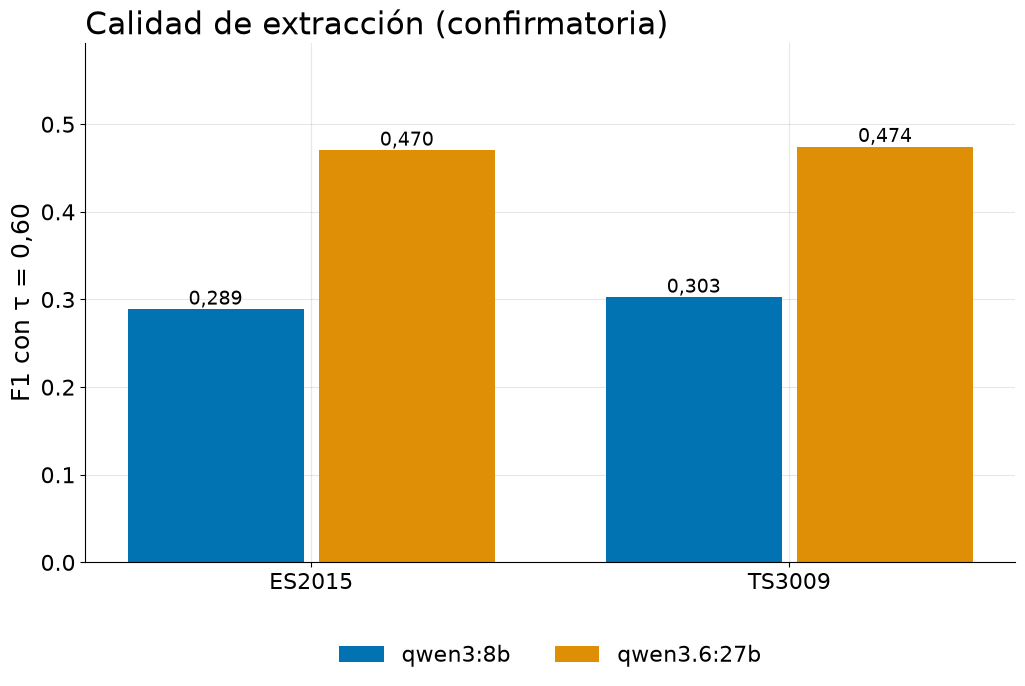

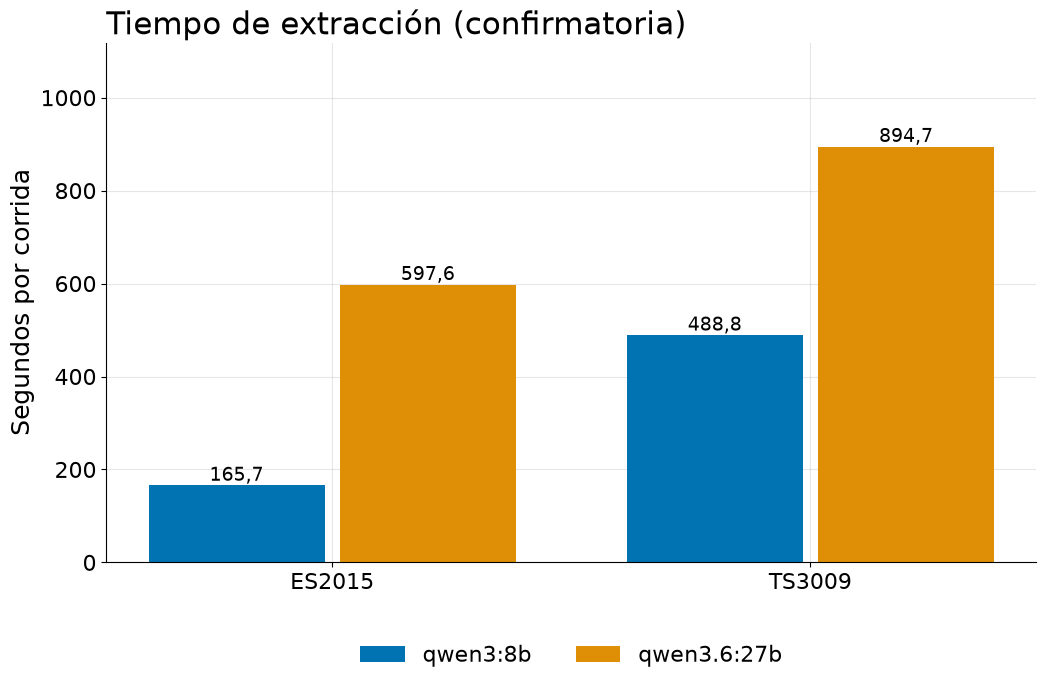

In [4]:
# F1 and time are drawn apart so the scales are not mixed.
f1_top = float(COMPARISON[["f1_baseline", "f1_candidate"]].to_numpy().max())
sec_top = float(COMPARISON[["seconds_baseline", "seconds_candidate"]].to_numpy().max())
with video_style():
    fig = plot_grouped_bars(
        SERIES,
        {
            BASELINE: list(COMPARISON["f1_baseline"]),
            CANDIDATE: list(COMPARISON["f1_candidate"]),
        },
        ylabel=f"F1 con τ = {es(SELECTION_TAU, 2)}",
        title="Calidad de extracción (confirmatoria)",
        ylim=(0, f1_top * 1.25),
        decimals=3,
    )
    display(fig)
    plt.close(fig)
    fig = plot_grouped_bars(
        SERIES,
        {
            BASELINE: list(COMPARISON["seconds_baseline"]),
            CANDIDATE: list(COMPARISON["seconds_candidate"]),
        },
        ylabel="Segundos por corrida",
        title="Tiempo de extracción (confirmatoria)",
        ylim=(0, sec_top * 1.25),
        decimals=1,
    )
    display(fig)
    plt.close(fig)

### **Resultado de la comparación**

In [5]:
ES, TS = COMPARISON.loc["ES2015"], COMPARISON.loc["TS3009"]
fail = {s: (int(r.failed_baseline), int(r.failed_candidate)) for s, r in COMPARISON.iterrows()}
md(
    f"`{CANDIDATE}` obtuvo un F1 mayor en ambas series. En ES2015 pasó de "
    f"**{es(ES.f1_baseline, 3)} a {es(ES.f1_candidate, 3)}**; en TS3009, de "
    f"**{es(TS.f1_baseline, 3)} a {es(TS.f1_candidate, 3)}**. El *recall* también aumentó y las "
    "corridas confirmatorias registraron menos reuniones fallidas con el modelo de mayor tamaño "
    f"({fail['ES2015'][0]} frente a {fail['ES2015'][1]} en ES2015; {fail['TS3009'][0]} "
    f"frente a {fail['TS3009'][1]} en TS3009).\n\n"
    "La diferencia aparece en el tiempo de procesamiento. En ES2015, el modelo mayor demoró "
    f"aproximadamente **{es(ES.time_ratio, 1)} veces** lo que tardó `{BASELINE}`. En TS3009, esa "
    f"relación fue de **{es(TS.time_ratio, 1)} veces**. No conviene resumir ambos valores en un "
    "único multiplicador: se comparan series distintas y el notebook 19 advierte que el tiempo "
    f"de `{BASELINE}` en TS3009 estuvo afectado por las reuniones fallidas.\n\n"
    "Estas pruebas muestran una mejora de calidad acompañada de una mayor latencia. **No "
    "resuelven por sí solas cuál extractor conviene adoptar**: la regla de selección sigue siendo "
    "la definida para el experimento y la decisión permanece abierta en el issue #143. Tampoco "
    "hay aquí mediciones de RAM/VRAM, consumo energético, costos financieros o desempeño en el "
    "conjunto reservado de evaluación.\n\n"
    "Para el video basta mostrar el cambio de F1 junto con el tiempo observado en cada serie. "
    "Esa comparación comunica mejor la decisión técnica que hablar de un «costo computacional» "
    "sin precisar qué se midió."
)

`qwen3.6:27b` obtuvo un F1 mayor en ambas series. En ES2015 pasó de **0,289 a 0,470**; en TS3009, de **0,303 a 0,474**. El *recall* también aumentó y las corridas confirmatorias registraron menos reuniones fallidas con el modelo de mayor tamaño (1 frente a 0 en ES2015; 6 frente a 4 en TS3009).

La diferencia aparece en el tiempo de procesamiento. En ES2015, el modelo mayor demoró aproximadamente **3,6 veces** lo que tardó `qwen3:8b`. En TS3009, esa relación fue de **1,8 veces**. No conviene resumir ambos valores en un único multiplicador: se comparan series distintas y el notebook 19 advierte que el tiempo de `qwen3:8b` en TS3009 estuvo afectado por las reuniones fallidas.

Estas pruebas muestran una mejora de calidad acompañada de una mayor latencia. **No resuelven por sí solas cuál extractor conviene adoptar**: la regla de selección sigue siendo la definida para el experimento y la decisión permanece abierta en el issue #143. Tampoco hay aquí mediciones de RAM/VRAM, consumo energético, costos financieros o desempeño en el conjunto reservado de evaluación.

Para el video basta mostrar el cambio de F1 junto con el tiempo observado en cada serie. Esa comparación comunica mejor la decisión técnica que hablar de un «costo computacional» sin precisar qué se midió.

# **2. Dónde se están produciendo los errores de C2**

La condición C2 construye una base de conocimiento a partir de las reuniones. Cuando falla una
respuesta, el problema puede haber ocurrido antes de la generación: durante la extracción de un
hecho o al recuperar los objetos que contienen la evidencia.

El análisis usa las preguntas de desarrollo de ES2015 y una corrida de C1 y una de C2. Se revisa
el estrato E1, de hechos puntuales. El origen de las fallas de C2 en E1 ya fue examinado en el
notebook 19 (§7.5; PR #177): una parte se atribuyó mediante una regla y el resto mediante
revisión humana. Aquí se retoma esa clasificación para ver dónde se concentran los problemas, sin
presentarla como una auditoría nueva ni extender sus conclusiones a otras series.

In [6]:
QUESTIONS = {q.id: q for q in load_experiment_questions(WORKSHEET_PATH)}
RECORDS = {
    name: load_records(path / RECORDS_FILE, latest_only=True) for name, path in B_RUNS.items()
}
E1 = {
    name: next(f for f in failure_split(rec) if f.stratum == "E1") for name, rec in RECORDS.items()
}
CONDITION_NAMES = {"C1": "C1 · RAG", "C2": "C2 · compilada"}
E1_TABLE = pd.DataFrame(
    [
        {
            "condición": CONDITION_NAMES[name],
            "preguntas": f.n,
            "correctas": f.correct,
            "respuesta incorrecta": f.wrong_answer,
            "abstención incorrecta": f.abstained_wrong,
            "fallas": f.n - f.correct,
            "exactitud": pct(f.correct / f.n),
        }
        for name, f in E1.items()
    ]
).set_index("condición")
md(
    f"**Estrato E1: {E1['C1'].n} preguntas de hechos puntuales por condición** "
    f"(de {len(QUESTIONS)} preguntas de desarrollo en total)."
)
E1_TABLE

**Estrato E1: 14 preguntas de hechos puntuales por condición** (de 21 preguntas de desarrollo en total).

,preguntas,correctas,respuesta incorrecta,abstención incorrecta,fallas,exactitud
condición,,,,,,
C1 · RAG,14,10,1,3,4,"71,4 %"
C2 · compilada,14,5,5,4,9,"35,7 %"


In [7]:
OE4_ROWS = read_worksheet_rows(OE4_SHEET)
OE4_E1 = [r for r in context_rows(RECORDS["C2"], RECORDS["C1"], QUESTIONS) if r.stratum == "E1"]
OE4_RULE = [
    "sintesis" for e in error_evidence(OE4_E1, RECORDS["C2"], QUESTIONS) if e.rule_stage is not None
]
OE4_STAGES = count_stages(OE4_RULE, OE4_ROWS)
N_FAILS = sum(OE4_STAGES.values())

STAGE_INFO = {
    "recuperacion": (
        "Recuperación",
        "La información estaba representada, pero no llegó al generador",
    ),
    "extraccion": ("Extracción", "El objeto persistido omitió o distorsionó el hecho"),
    "sintesis": ("Síntesis", "La evidencia seleccionada no produjo la respuesta esperada"),
}
SHARES = stage_shares({stage: OE4_STAGES[stage] for stage in STAGE_INFO})
STAGE_TABLE = pd.DataFrame(
    {
        "etapa": [STAGE_INFO[s][0] for s in SHARES.index],
        "casos": SHARES["cases"].to_numpy(),
        f"porcentaje de las {N_FAILS} fallas": [pct(v) for v in SHARES["share"]],
        "interpretación": [STAGE_INFO[s][1] for s in SHARES.index],
    }
).set_index("etapa")
md(
    f"**Etapa probable de las {N_FAILS} fallas E1 de C2.** Atribución por regla (síntesis): "
    f"{len(OE4_RULE)}; por revisión humana: {len(OE4_ROWS)}."
)
STAGE_TABLE

**Etapa probable de las 9 fallas E1 de C2.** Atribución por regla (síntesis): 1; por revisión humana: 8.

,casos,porcentaje de las 9 fallas,interpretación
etapa,,,
Recuperación,4,"44,4 %","La información estaba representada, pero no llegó al generador"
Extracción,3,"33,3 %",El objeto persistido omitió o distorsionó el hecho
Síntesis,2,"22,2 %",La evidencia seleccionada no produjo la respuesta esperada


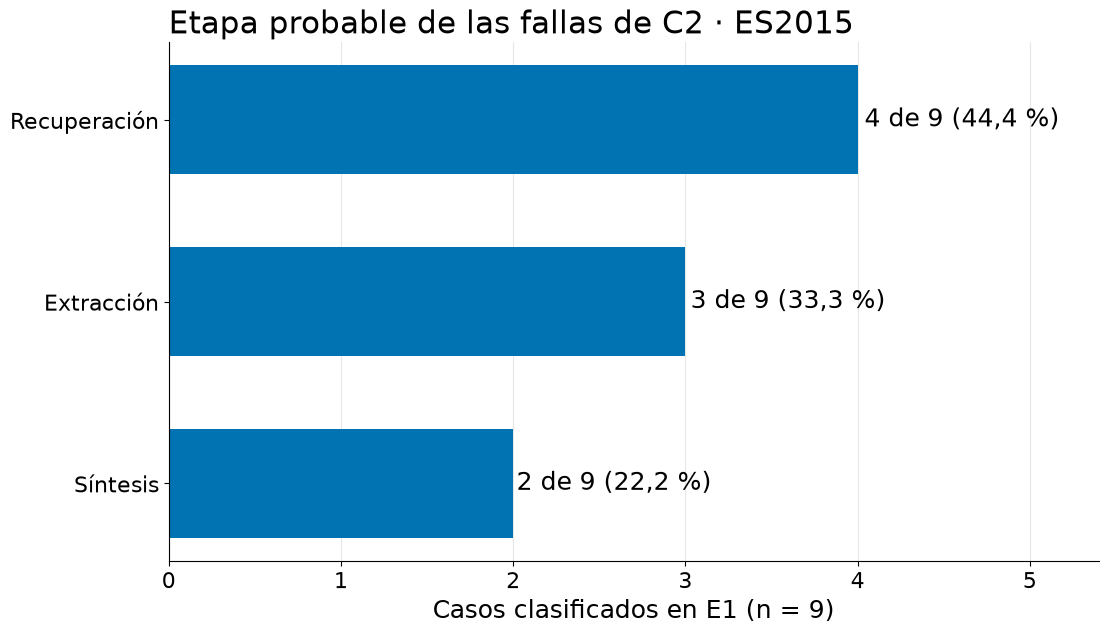

In [8]:
with video_style():
    fig = plot_hbars(
        {STAGE_INFO[s][0]: float(SHARES.loc[s, "cases"]) for s in SHARES.index},
        annotations=[
            f"{int(SHARES.loc[s, 'cases'])} de {N_FAILS} ({pct(SHARES.loc[s, 'share'])})"
            for s in SHARES.index
        ],
        xlabel=f"Casos clasificados en E1 (n = {N_FAILS})",
        title="Etapa probable de las fallas de C2 · ES2015",
    )
    display(fig)
    plt.close(fig)

### **Qué muestra el desglose**

In [9]:
c2 = E1["C2"]
n_ret, n_ext, n_syn = (OE4_STAGES[s] for s in ("recuperacion", "extraccion", "sintesis"))
md(
    f"**{n_ret} de las {N_FAILS} fallas se atribuyeron a recuperación.** La información estaba "
    "representada en la base compilada, pero no llegó al contexto utilizado para responder. El "
    "notebook 19 documenta, por ejemplo, una recuperación sobre DVD/VCR cuando la consulta exigía "
    "identificar la exclusión del teletexto. Esto apunta a revisar la pertinencia de los objetos "
    "seleccionados. No permite asegurar todavía que cambiar el índice vaya a mejorar la "
    "exactitud.\n\n"
    f"**En otros {n_ext} casos, el problema se originó en la extracción.** El objeto guardado "
    "contenía una aproximación, omitía parte del hecho o registraba una propuesta descartada "
    "como decisión. Si ese contenido se recupera posteriormente, el buscador puede estar "
    "funcionando correctamente y aun así entregar información equivocada. Por eso importa volver "
    "a la transcripción y comprobar el estado de cada decisión.\n\n"
    f"**Las {n_syn} fallas restantes se atribuyeron a la síntesis de la respuesta.** El "
    "notebook 19 también identifica resúmenes truncados y advierte sobre un posible falso "
    "negativo del juez en `q023`. Este último punto merece una revisión aparte: un error al "
    "calificar una respuesta no debe confundirse con un error del sistema que la generó. Para "
    "comprobar cada caso individual hay que contrastar el diagnóstico con `oe4-etapa-e1.csv`, "
    "la hoja de la que se leen las etiquetas humanas.\n\n"
    f"En total, C2 acumuló **{c2.wrong_answer} respuestas equivocadas y {c2.abstained_wrong} "
    "abstenciones incorrectas** en E1. Que "
    f"{n_ret} de las {N_FAILS} fallas hayan ocurrido durante la recuperación es una pista útil "
    "para priorizar revisiones, pero la muestra es pequeña. No se extrapolan esas proporciones a "
    "todo OpenKOS ni al estrato E3 de evolución, donde se probó solo una pregunta."
)

**4 de las 9 fallas se atribuyeron a recuperación.** La información estaba representada en la base compilada, pero no llegó al contexto utilizado para responder. El notebook 19 documenta, por ejemplo, una recuperación sobre DVD/VCR cuando la consulta exigía identificar la exclusión del teletexto. Esto apunta a revisar la pertinencia de los objetos seleccionados. No permite asegurar todavía que cambiar el índice vaya a mejorar la exactitud.

**En otros 3 casos, el problema se originó en la extracción.** El objeto guardado contenía una aproximación, omitía parte del hecho o registraba una propuesta descartada como decisión. Si ese contenido se recupera posteriormente, el buscador puede estar funcionando correctamente y aun así entregar información equivocada. Por eso importa volver a la transcripción y comprobar el estado de cada decisión.

**Las 2 fallas restantes se atribuyeron a la síntesis de la respuesta.** El notebook 19 también identifica resúmenes truncados y advierte sobre un posible falso negativo del juez en `q023`. Este último punto merece una revisión aparte: un error al calificar una respuesta no debe confundirse con un error del sistema que la generó. Para comprobar cada caso individual hay que contrastar el diagnóstico con `oe4-etapa-e1.csv`, la hoja de la que se leen las etiquetas humanas.

En total, C2 acumuló **5 respuestas equivocadas y 4 abstenciones incorrectas** en E1. Que 4 de las 9 fallas hayan ocurrido durante la recuperación es una pista útil para priorizar revisiones, pero la muestra es pequeña. No se extrapolan esas proporciones a todo OpenKOS ni al estrato E3 de evolución, donde se probó solo una pregunta.

# **3. Comparabilidad entre C1 y C2**

La comparación busca establecer qué cambia cuando las respuestas se apoyan en **transcripciones
recuperadas (C1)** o en una **base compilada automáticamente (C2)**. Para interpretar esa
diferencia hay que comprobar que otras partes del proceso no introduzcan ventajas o restricciones
adicionales.

El notebook 19 deja documentados varios componentes compartidos, junto con algunas diferencias que
todavía deben resolverse. Se ordenan esas observaciones en una tabla para distinguir qué está
definido, qué hay que verificar durante la ejecución y qué sigue siendo una decisión del equipo.

La revisión se basa en las secciones 4, 5.6, 8.2, 9 y 11 del notebook 19. **No se inspeccionaron
las implementaciones actuales** ni se comprobó todavía la equivalencia de las corridas finales. La
tabla es texto documental, no un cálculo.

In [10]:
CONTROLS = pd.DataFrame(
    [
        {
            "componente": "Generador",
            "situación": "Compartido por diseño",
            "evidencia": f"{SB['generative_model']} en C1 y C2",
            "verificación": "Confirmar el modelo y su digest en cada corrida",
        },
        {
            "componente": "Embeddings",
            "situación": "Compartido por diseño",
            "evidencia": f"{SB['embedding_model']} según la configuración declarada",
            "verificación": "Registrar versión y huella de cada backend",
        },
        {
            "componente": "Contexto efectivo",
            "situación": "Mecanismo documentado",
            "evidencia": "Recorte alineado con OpenKOS (ADR 0007)",
            "verificación": "Comparar el texto efectivo entregado, no únicamente K o el límite "
            "nominal",
        },
        {
            "componente": "Prompts de respuesta",
            "situación": "Copiados con limitación",
            "evidencia": "C1 utiliza instrucciones copiadas de OpenKOS (ADR 0006)",
            "verificación": "Revisar que las menciones a bundle/objetos no favorezcan a C2",
        },
        {
            "componente": "Suficiencia",
            "situación": "Pendiente de homologación",
            "evidencia": "La rama principal de OpenKOS puede verificar con otro modelo; la 0.6.0 "
            "no tiene ese cambio",
            "verificación": f"Fijar versión o forzar {SB['generative_model']} para suficiencia "
            "(issue #94)",
        },
        {
            "componente": "Fuentes originales en C2",
            "situación": "Decisión abierta",
            "evidencia": "OpenKOS puede conservar y recuperar sources/ (issue #146)",
            "verificación": "Establecer si C2 puede acceder a transcripciones originales",
        },
        {
            "componente": "Procedencia",
            "situación": "Por verificar en corrida formal",
            "evidencia": "El notebook 19 registra diferencias entre manifiestos de desarrollo",
            "verificación": "Registrar versiones, commits, modelos y configuraciones congeladas",
        },
    ]
).set_index("componente")
CONTROLS

,situación,evidencia,verificación
componente,,,
Generador,Compartido por diseño,qwen3:8b en C1 y C2,Confirmar el modelo y su digest en cada corrida
Embeddings,Compartido por diseño,bge-m3 según la configuración declarada,Registrar versión y huella de cada backend
Contexto efectivo,Mecanismo documentado,Recorte alineado con OpenKOS (ADR 0007),"Comparar el texto efectivo entregado, no únicamente K o el límite nominal"
Prompts de respuesta,Copiados con limitación,C1 utiliza instrucciones copiadas de OpenKOS (ADR 0006),Revisar que las menciones a bundle/objetos no favorezcan a C2
Suficiencia,Pendiente de homologación,La rama principal de OpenKOS puede verificar con otro modelo; la 0.6.0 no tiene ese cambio,Fijar versión o forzar qwen3:8b para suficiencia (issue #94)
Fuentes originales en C2,Decisión abierta,OpenKOS puede conservar y recuperar sources/ (issue #146),Establecer si C2 puede acceder a transcripciones originales
Procedencia,Por verificar en corrida formal,El notebook 19 registra diferencias entre manifiestos de desarrollo,"Registrar versiones, commits, modelos y configuraciones congeladas"


### **Qué hay que comprobar antes de la evaluación**

El generador y el modelo de *embeddings* están declarados como compartidos entre C1 y C2. Eso
ayuda a controlar el experimento, pero no basta para atribuir cualquier diferencia de respuestas
exclusivamente a la representación del conocimiento.

Hay dos puntos especialmente sensibles. La **verificación de suficiencia** puede modificar cuándo
se responde y cuándo se produce una abstención, incluso si la evidencia disponible es parecida.
Además, si C2 puede consultar archivos originales en `sources/`, el sistema no estaría operando
únicamente sobre los objetos compilados. Ambos asuntos están registrados en los issues **#94** y
**#146**.

Conviene mantener esos puntos visibles hasta que se fijen las versiones y configuraciones de las
corridas finales. Con la evidencia actual se puede explicar **qué controles están previstos**,
pero todavía no afirmar que C1 y C2 se diferencian solamente por la representación consultada.

# **4. Procedencia y comprobaciones**

Las cifras de este notebook no se copian: se leen de los archivos listados abajo, con las
mismas funciones que usa el notebook 19. La celda siguiente comprueba que las lecturas de las
secciones 1 y 2 siguen describiendo los datos y que el tiempo calculado coincide con el de
`screen_costs`. **No reemplaza la ejecución de los modelos ni la revisión de las anotaciones
humanas**: los casos individuales y las versiones de cada componente deben cotejarse con los
archivos del repositorio.

In [11]:
SOURCES = pd.DataFrame(
    [
        ("Confirmatoria del extractor", CONFIRM_FILE),
        ("Registros de C1 (una corrida)", B_RUNS["C1"] / RECORDS_FILE),
        ("Registros de C2 (una corrida)", B_RUNS["C2"] / RECORDS_FILE),
        ("Etiquetas humanas de etapa (OE4)", OE4_SHEET),
    ],
    columns=["dato", "archivo"],
).set_index("dato")
SOURCES["archivo"] = [p.relative_to(PROJECT_ROOT).as_posix() for p in SOURCES["archivo"]]

# The readings above state these facts; if a stored result changes them, fail here.
assert (COMPARISON["d_f1"] > 0).all() and (COMPARISON["d_recall"] > 0).all()
assert (COMPARISON["time_ratio"] > 1).all()
assert (COMPARISON["failed_candidate"] < COMPARISON["failed_baseline"]).all()
costs = {
    (c.model, c.activity.split()[-1]): c.ratio
    for c in screen_costs(CONFIRM_SCORED, phase="confirmatoria", baseline=BASELINE)
}
for series, row in COMPARISON.iterrows():
    assert abs(costs[(CANDIDATE, series)] - row["time_ratio"]) < 1e-9
assert all(len({r["run"] for r in rec}) == 1 for rec in RECORDS.values())
assert all(f.correct + f.wrong_answer + f.abstained_wrong == f.n for f in E1.values())
assert E1["C2"].n - E1["C2"].correct == N_FAILS
md("**Comprobaciones superadas.** Las lecturas coinciden con los resultados guardados.")
SOURCES

**Comprobaciones superadas.** Las lecturas coinciden con los resultados guardados.

,archivo
dato,
Confirmatoria del extractor,reports/experiment-a/model-screen-openkos/confirm/scored.json
Registros de C1 (una corrida),reports/experiment-b/humo-c1-es2015/respuestas.jsonl
Registros de C2 (una corrida),reports/experiment-b/humo-c2-es2015-conceptos/respuestas.jsonl
Etiquetas humanas de etapa (OE4),reports/experiment-b/humo-c2-es2015-conceptos/oe4-etapa-e1.csv


# **5. Resumen y siguiente revisión**

Los resultados permiten precisar tres aspectos del modelado sin incorporar nuevas pruebas:

- El extractor de mayor tamaño mejora el F1 en las dos series de desarrollo, pero requiere más
  tiempo por corrida. La selección definitiva sigue abierta (issue #143).
- En las fallas E1 revisadas de C2, la recuperación concentra la mayor parte de los casos, la
  extracción y la síntesis el resto. Es una pista para investigar, no una estimación general del
  comportamiento del sistema.
- C1 y C2 comparten componentes por diseño, aunque todavía hay que comprobar las condiciones
  efectivas de ejecución y resolver las diferencias documentadas.

Estos análisis se reflejan también en el notebook 19: la comparación de F1 y tiempo en la sección
5.3, la lista de controles en la sección 5.6 y el desglose por etapa en la sección 7.5. Este
notebook sigue siendo el lugar donde se leen juntos, con su contexto, sin dar por resueltos los
issues #94 y #146.